In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import warnings
warnings.filterwarnings('ignore')

# ── Sklearn ─────────────────────────────────────────────────────
from sklearn.linear_model       import LinearRegression
from sklearn.ensemble           import RandomForestRegressor
from sklearn.neural_network     import MLPRegressor
from sklearn.preprocessing      import StandardScaler
from sklearn.metrics            import mean_squared_error, mean_absolute_error, r2_score

# ── XGBoost ─────────────────────────────────────────────────────
from xgboost import XGBRegressor

# ── Deep Learning ───────────────────────────────────────────────
from tensorflow.keras.models    import Sequential
from tensorflow.keras.layers    import LSTM, Dense, Dropout
from tensorflow.keras.callbacks import EarlyStopping
import tensorflow as tf

In [ ]:
df = pd.read_csv(r'E:\2025.2\DAV\data\Power_solar_Sonla.csv')
RANDOM_STATE = 42
NIGHT_FILTER = True
SZA_THRESHOLD = 90
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 52601 entries, 0 to 52600
Data columns (total 18 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   datetime_vn         52601 non-null  str    
 1   year                52601 non-null  int64  
 2   month               52601 non-null  int64  
 3   day                 52601 non-null  int64  
 4   hour                52601 non-null  int64  
 5   T2M                 52601 non-null  float64
 6   RH2M                52601 non-null  float64
 7   PRECTOTCORR         52601 non-null  float64
 8   T2MDEW              52601 non-null  float64
 9   WS10M               52601 non-null  float64
 10  WD10M               52601 non-null  float64
 11  ALLSKY_SRF_ALB      52601 non-null  float64
 12  ALLSKY_SFC_SW_DWN   52601 non-null  float64
 13  ALLSKY_SFC_SW_DNI   52601 non-null  float64
 14  ALLSKY_SFC_SW_DIFF  52601 non-null  float64
 15  ALLSKY_KT           52601 non-null  float64
 16  SZA            

In [ ]:
if NIGHT_FILTER:
    df_day = df[df['SZA'] < SZA_THRESHOLD].copy()
    df_day.reset_index(drop=True, inplace=True)
    print(f"\n[NIGHT_FILTER = True]")
    print(f"Trước lọc : {len(df):,} rows")
    print(f"Sau lọc   : {len(df_day):,} rows")
    print(f"Đã loại   : {len(df) - len(df_day):,} rows ban đêm "
          f"({(len(df) - len(df_day)) / len(df) * 100:.1f}%)")
else:
    df_day = df.copy()
    print(f"\n[NIGHT_FILTER = False] Giữ toàn bộ {len(df_day):,} rows")

print(f"\nShape sau xử lý: {df_day.shape}")


[NIGHT_FILTER = True]
Trước lọc : 52,601 rows
Sau lọc   : 27,487 rows
Đã loại   : 25,114 rows ban đêm (47.7%)

Shape sau xử lý: (27487, 18)


In [ ]:
ISC = 1367  # Hằng số mặt trời (W/m²)

LEAKAGE_COLS = [
    'ALLSKY_SFC_SW_DWN',   # chính là GHI → target gián tiếp
    'ALLSKY_SFC_SW_DNI',   # tính từ GHI
    'ALLSKY_SFC_SW_DIFF',  # tính từ GHI
    'ALLSKY_SRF_ALB',      # phụ thuộc GHI
]

FEATURES = [
    # Thời gian
    'hour_sin', 'hour_cos', 'month_sin', 'month_cos', ''
    # Khí tượng
    'T2M', 'RH2M', 'PRECTOTCORR',
    # Gió
    'WS10M',
    # Bức xạ
    'SZA', 'H0', 'CLRSKY_SFC_SW_DWN',
]

TARGET = 'ALLSKY_KT'

def feature_engineering(df: pd.DataFrame) -> pd.DataFrame:

    df = df.copy()

    # ── 1. Lưu GHI actual (trước khi drop) ─────────────────────
    df['GHI_actual'] = df['ALLSKY_SFC_SW_DWN']

    # ── 2. Cyclic encoding ──────────────────────────────────────
    df['hour_sin']  = np.sin(2 * np.pi * df['hour']  / 24)
    df['hour_cos']  = np.cos(2 * np.pi * df['hour']  / 24)
    df['month_sin'] = np.sin(2 * np.pi * df['month'] / 12)
    df['month_cos'] = np.cos(2 * np.pi * df['month'] / 12)

    # ── 3. Tính H0 ──────────────────────────────────────────────
    df['day_of_year'] = pd.to_datetime(df[['year', 'month', 'day']]).dt.dayofyear
    df['H0'] = df['GHI_actual'] / df['ALLSKY_KT']
    df['H0']  = df['H0'].clip(lower=0)

    # ── 4. Drop leakage columns ─────────────────────────────────
    df.drop(columns=LEAKAGE_COLS, inplace=True)


    print("=" * 50)
    print(f"Feature Engineering hoàn tất")
    print(f"Shape          : {df.shape}")
    print(f"Features ({len(FEATURES)}): {FEATURES}")
    print(f"Target         : {TARGET}")
    print(f"\nThống kê target ({TARGET}):")
    print(df[TARGET].describe().round(3))
    print("=" * 50)

    return df

# ════════════════════════════════════════════════════════════════
# Chạy
# ════════════════════════════════════════════════════════════════
df_fe = feature_engineering(df_day)

Feature Engineering hoàn tất
Shape          : (27487, 21)
Features (11): ['hour_sin', 'hour_cos', 'month_sin', 'month_cos', 'T2M', 'RH2M', 'PRECTOTCORR', 'WS10M', 'SZA', 'H0', 'CLRSKY_SFC_SW_DWN']
Target         : ALLSKY_KT

Thống kê target (ALLSKY_KT):
count    27487.000
mean         0.400
std          0.173
min          0.020
25%          0.260
50%          0.400
75%          0.540
max          0.800
Name: ALLSKY_KT, dtype: float64


In [ ]:
# ── CONFIG ──────────────────────────────────────────────────────
FEATURES = [
    'hour_sin', 'hour_cos', 'month_sin', 'month_cos',
    'T2M', 'RH2M', 'PRECTOTCORR', 'WS10M',
    'SZA', 'H0', 'CLRSKY_SFC_SW_DWN',
]
TARGET = 'ALLSKY_KT'

# ════════════════════════════════════════════════════════════════
# Split
# ════════════════════════════════════════════════════════════════
def train_val_test_split(df: pd.DataFrame):
    df = df.copy()
    df['datetime_vn'] = pd.to_datetime(df['datetime_vn'])

    train_mask = (df['datetime_vn'] >= '2020-01-01') & (df['datetime_vn'] < '2025-03-01')
    val_mask   = (df['datetime_vn'] >= '2025-03-01') & (df['datetime_vn'] < '2025-09-01')
    test_mask  =  df['datetime_vn'] >= '2025-09-01'

    train = df[train_mask]
    val   = df[val_mask]
    test  = df[test_mask]

    X_train = train[FEATURES].values
    y_train = train[TARGET].values
    X_val   = val[FEATURES].values
    y_val   = val[TARGET].values
    X_test  = test[FEATURES].values
    y_test  = test[TARGET].values

    H0_val   = val['H0'].values        # ← thêm
    GHI_val  = val['GHI_actual'].values  # ← thêm
    H0_test  = test['H0'].values
    GHI_test = test['GHI_actual'].values

    return (X_train, X_val, X_test,
            y_train, y_val, y_test,
            H0_val, GHI_val,          # ← thêm
            H0_test, GHI_test)

X_train, X_val, X_test, \
y_train, y_val, y_test, \
H0_val, GHI_val,         \
H0_test, GHI_test = train_val_test_split(df_fe)

# ── Scaler (dùng cho MLP và LSTM) ───────────────────────────────
scaler     = StandardScaler()
X_train_sc = scaler.fit_transform(X_train)
X_val_sc   = scaler.transform(X_val)
X_test_sc  = scaler.transform(X_test)

In [ ]:
def evaluate_kt(name, y_true, y_pred):
    # ── Metrics cơ bản ───────────────────────────────────────────
    rmse  = np.sqrt(mean_squared_error(y_true, y_pred))
    mae   = mean_absolute_error(y_true, y_pred)
    r2    = r2_score(y_true, y_pred)



    # ── Paper 2: rRMSE, rMAE (normalize theo mean) ──────────────
    # Về công thức tương đương NRMSE nhưng Paper 2 gọi là relative
    rrmse = rmse / np.mean(y_true)                  # dimensionless


    # ── Paper 3: MAPE, MBE ──────────────────────────────────────
    mape  = np.mean(np.abs((y_true - y_pred)
                           / (y_true + 1e-6))) * 100  # %
    print(
        f"{name:20s} | "
        f"RMSE={rmse:.4f} | MAE={mae:.4f} | R²={r2:.4f} | "

        f"rRMSE={rrmse:.4f} | "  # Paper 2
        f"MAPE={mape:.2f}% | "       # Paper 3
    )

    return {
        'Model' : name,
        # Cơ bản
        'RMSE'  : rmse,
        'MAE'   : mae,
        'R2'    : r2,
       
        # Paper 2
        'rRMSE' : rrmse,

        # Paper 3
        'MAPE(%)' : mape,
    
    }

results = []

In [ ]:
lr = LinearRegression()
lr.fit(X_train_sc, y_train)
pred_lr = lr.predict(X_test_sc)
results.append(evaluate_kt("LinearRegression", y_test, pred_lr))

LinearRegression     | RMSE=0.1140 | MAE=0.0899 | R²=0.5288 | rRMSE=0.2765 | MAPE=29.31% | 


In [ ]:
rf = RandomForestRegressor(
        n_estimators=200,
        max_depth=15,
        min_samples_leaf=5,
        n_jobs=-1,
        random_state=RANDOM_STATE
    )
rf.fit(X_train, y_train)
pred_rf = rf.predict(X_test)
results.append(evaluate_kt("RandomForest", y_test, pred_rf))

RandomForest         | RMSE=0.0914 | MAE=0.0700 | R²=0.6974 | rRMSE=0.2216 | MAPE=23.25% | 


In [ ]:
xgb = XGBRegressor(
        n_estimators=500,
        max_depth=6,
        learning_rate=0.05,
        subsample=0.8,
        colsample_bytree=0.8,
        random_state=RANDOM_STATE,
        n_jobs=-1,
        verbosity=0
    )
xgb.fit(
        X_train, y_train,
        eval_set=[(X_val, y_val)],
        verbose=False
    )
pred_xgb = xgb.predict(X_test)
results.append(evaluate_kt("XGBoost", y_test, pred_xgb))

XGBoost              | RMSE=0.0884 | MAE=0.0663 | R²=0.7168 | rRMSE=0.2143 | MAPE=22.45% | 


In [ ]:
mlp = MLPRegressor(
        hidden_layer_sizes=(128, 64, 32),
        activation='relu',
        max_iter=500,
        early_stopping=True,
        validation_fraction=0.1,
        random_state=RANDOM_STATE
    )
mlp.fit(X_train_sc, y_train)
pred_mlp = mlp.predict(X_test_sc)
results.append(evaluate_kt("MLP", y_test, pred_mlp))

MLP                  | RMSE=0.0971 | MAE=0.0725 | R²=0.6579 | rRMSE=0.2356 | MAPE=22.92% | 


In [ ]:
def create_sequences(X, y, window=12):
    Xs, ys = [], []
    for i in range(window, len(X)):
        Xs.append(X[i-window:i])
        ys.append(y[i])
    return np.array(Xs), np.array(ys)

WINDOW = 12
X_train_seq, y_train_seq = create_sequences(X_train_sc, y_train, WINDOW)
X_val_seq,   y_val_seq   = create_sequences(X_val_sc,   y_val,   WINDOW)
X_test_seq,  y_test_seq  = create_sequences(X_test_sc,  y_test,  WINDOW)

lstm_model = Sequential([
    LSTM(64, input_shape=(WINDOW, X_train_sc.shape[1]), return_sequences=True),
    Dropout(0.2),
    LSTM(32, return_sequences=False),
    Dropout(0.2),
    Dense(16, activation='relu'),
    Dense(1)
])
lstm_model.compile(optimizer='adam', loss='mse')

es = EarlyStopping(
    monitor='val_loss',
    patience=10,
    restore_best_weights=True
)
lstm_model.fit(
    X_train_seq, y_train_seq,
    validation_data=(X_val_seq, y_val_seq),
    epochs=100,
    batch_size=256,
    callbacks=[es],
    verbose=0
)
pred_lstm = lstm_model.predict(X_test_seq, verbose=0).flatten()
results.append(evaluate_kt("LSTM", y_test_seq, pred_lstm))

LSTM                 | RMSE=0.0897 | MAE=0.0691 | R²=0.7101 | rRMSE=0.2177 | MAPE=21.89% | 


In [ ]:
results_df = pd.DataFrame(results).sort_values('RMSE').reset_index(drop=True)

print("\n══ Model Comparison (KT — Test Set) ══")
print(results_df.to_string(index=False))
print(f"\n✅ Best model: {results_df.iloc[0]['Model']}")


══ Model Comparison (KT — Test Set) ══
           Model     RMSE      MAE       R2    rRMSE   MAPE(%)
         XGBoost 0.088377 0.066333 0.716839 0.214316 22.448633
            LSTM 0.089672 0.069106 0.710115 0.217655 21.893373
    RandomForest 0.091367 0.069979 0.697357 0.221566 23.248134
             MLP 0.097147 0.072520 0.657855 0.235583 22.918315
LinearRegression 0.114010 0.089869 0.528763 0.276476 29.306112

✅ Best model: XGBoost


In [ ]:
def recover_ghi(kt_pred: np.ndarray, H0: np.ndarray) -> np.ndarray:
    """
    Tính GHI từ K_T predicted và H0.
        GHI = clip(K_T, 0, 1) × H0
    """
    kt_clipped = np.clip(kt_pred, 0, 1)
    return kt_clipped * H0

def evaluate_ghi(name, ghi_true, ghi_pred):
    rmse = np.sqrt(mean_squared_error(ghi_true, ghi_pred))
    mae  = mean_absolute_error(ghi_true, ghi_pred)
    r2   = r2_score(ghi_true, ghi_pred)
    mape = np.mean(np.abs((ghi_true - ghi_pred) / (ghi_true + 1e-6))) * 100
    print(f"{name:20s} | RMSE={rmse:.2f} W/m² | MAE={mae:.2f} | R²={r2:.4f} | MAPE={mape:.2f}%")
    return {'Model': name, 'RMSE': rmse, 'MAE': mae, 'R2': r2, 'MAPE': mape}

In [ ]:
OFFSET = WINDOW  # = 12

predictions = {}
predictions['LinearRegression'] = (pred_lr,   H0_test,           GHI_test)
predictions['RandomForest']     = (pred_rf,   H0_test,           GHI_test)
predictions['XGBoost']          = (pred_xgb,  H0_test,           GHI_test)
predictions['MLP']              = (pred_mlp,  H0_test,           GHI_test)
predictions['LSTM']             = (pred_lstm, H0_test[OFFSET:],  GHI_test[OFFSET:])

ghi_results = []

print("══ GHI Recovery (Test Set) ══")
for name, values in predictions.items():
    kt_pred  = values[0]
    h0       = values[1]
    ghi_true = values[2]
    ghi_pred = recover_ghi(kt_pred, h0)
    ghi_results.append(evaluate_ghi(name, ghi_true, ghi_pred))

ghi_df = pd.DataFrame(ghi_results).sort_values('RMSE').reset_index(drop=True)

print("\n══ GHI Model Comparison ══")
print(ghi_df.to_string(index=False))
print(f"\n✅ Best model for GHI: {ghi_df.iloc[0]['Model']}")


══ GHI Recovery (Test Set) ══
LinearRegression     | RMSE=91.77 W/m² | MAE=64.20 | R²=0.8366 | MAPE=29.19%
RandomForest         | RMSE=78.92 W/m² | MAE=52.31 | R²=0.8792 | MAPE=23.25%
XGBoost              | RMSE=76.77 W/m² | MAE=49.69 | R²=0.8857 | MAPE=22.45%
MLP                  | RMSE=85.15 W/m² | MAE=54.98 | R²=0.8593 | MAPE=22.92%
LSTM                 | RMSE=76.19 W/m² | MAE=51.59 | R²=0.8873 | MAPE=21.89%

══ GHI Model Comparison ══
           Model      RMSE       MAE       R2      MAPE
            LSTM 76.187080 51.585578 0.887261 21.893478
         XGBoost 76.770087 49.693783 0.885654 22.448746
    RandomForest 78.922229 52.309871 0.879153 23.248249
             MLP 85.149652 54.977915 0.859330 22.918420
LinearRegression 91.774300 64.195583 0.836590 29.190112

✅ Best model for GHI: LSTM


#### Tunning

In [ ]:
from sklearn.model_selection import RandomizedSearchCV, PredefinedSplit
from sklearn.neural_network  import MLPRegressor

In [ ]:
results_tuned = []

In [ ]:
split_index = np.concatenate([
    np.full(len(X_train), -1),
    np.zeros(len(X_val))
])
ps = PredefinedSplit(split_index)

X_trainval    = np.concatenate([X_train,    X_val])
X_trainval_sc = np.concatenate([X_train_sc, X_val_sc])
y_trainval    = np.concatenate([y_train,    y_val])

N_ITER  = 30
CV_JOBS = -1

In [ ]:
from sklearn.linear_model import Ridge

ridge_param_dist = {
    'alpha': [0.001, 0.01, 0.1, 1.0, 10.0, 100.0, 1000.0],
}

ridge_search = RandomizedSearchCV(
    Ridge(),
    param_distributions=ridge_param_dist,
    n_iter=7,                              # bằng đúng số candidates
    scoring='neg_root_mean_squared_error',
    cv=ps,                                 # PredefinedSplit đã tạo ở trên
    refit=False,
    random_state=RANDOM_STATE,
    n_jobs=-1,
    verbose=1,
)
ridge_search.fit(X_trainval_sc, y_trainval)

print("Ridge best params:", ridge_search.best_params_)

lr_tuned = Ridge(**ridge_search.best_params_)
lr_tuned.fit(X_train_sc, y_train)
pred_lr_tuned = lr_tuned.predict(X_test_sc)
results_tuned.append(evaluate_kt("Ridge (tuned)", y_test, pred_lr_tuned))

Fitting 1 folds for each of 7 candidates, totalling 7 fits
Ridge best params: {'alpha': 100.0}
Ridge (tuned)        | RMSE=0.1142 | MAE=0.0901 | R²=0.5272 | rRMSE=0.2769 | MAPE=29.33% | 


In [ ]:
rf_param_dist = {
    'n_estimators'    : [200, 300, 400, 500],
    'max_depth'       : [10, 15, 20, 25, None],
    'min_samples_leaf': [1, 2, 3, 5],
    'max_features'    : [0.5, 0.6, 0.7, 0.8],
    'min_samples_split': [2, 5, 10],
}

rf_search = RandomizedSearchCV(
    RandomForestRegressor(n_jobs=-1, random_state=RANDOM_STATE),
    param_distributions=rf_param_dist,
    n_iter=30,
    scoring='neg_root_mean_squared_error',
    cv=ps,                  # PredefinedSplit đã tạo ở trên
    refit=False,
    random_state=RANDOM_STATE,
    n_jobs=-1,
    verbose=1,
)
rf_search.fit(X_trainval, y_trainval)

print("RF best params:", rf_search.best_params_)

rf_tuned = RandomForestRegressor(
    **rf_search.best_params_,
    n_jobs=-1,
    random_state=RANDOM_STATE,
)
rf_tuned.fit(X_train, y_train)
pred_rf_tuned = rf_tuned.predict(X_test)
results_tuned.append(evaluate_kt("RandomForest (tuned)", y_test, pred_rf_tuned))

Fitting 1 folds for each of 30 candidates, totalling 30 fits
RF best params: {'n_estimators': 400, 'min_samples_split': 5, 'min_samples_leaf': 1, 'max_features': 0.5, 'max_depth': 25}
RandomForest (tuned) | RMSE=0.0905 | MAE=0.0695 | R²=0.7031 | rRMSE=0.2195 | MAPE=23.26% | 


In [ ]:
xgb_param_dist = {
    'n_estimators'     : [400, 500, 600, 700, 800],
    'max_depth'        : [5, 6, 7, 8, 9],
    'learning_rate'    : [0.01, 0.03, 0.05, 0.07, 0.1],
    'subsample'        : [0.7, 0.8, 0.9, 1.0],
    'colsample_bytree' : [0.6, 0.7, 0.8, 0.9],
    'min_child_weight' : [1, 3, 5],
    'gamma'            : [0, 0.01, 0.05, 0.1],
}

xgb_search = RandomizedSearchCV(
    XGBRegressor(
        random_state=RANDOM_STATE,
        n_jobs=-1,
        verbosity=0,
        early_stopping_rounds=20,
        eval_metric='rmse',
    ),
    param_distributions=xgb_param_dist,
    n_iter=N_ITER,
    scoring='neg_root_mean_squared_error',
    cv=ps,
    refit=False,
    random_state=RANDOM_STATE,
    n_jobs=CV_JOBS,
    verbose=1,
)
xgb_search.fit(
    X_trainval, y_trainval,
    eval_set=[(X_val, y_val)],
)

print("XGBoost best params:", xgb_search.best_params_)

xgb_tuned = XGBRegressor(
    **xgb_search.best_params_,
    random_state=RANDOM_STATE,
    n_jobs=-1,
    verbosity=0,
    early_stopping_rounds=20,
    eval_metric='rmse',
)
xgb_tuned.fit(
    X_train, y_train,
    eval_set=[(X_val, y_val)],
    verbose=False,
)
pred_xgb_tuned = xgb_tuned.predict(X_test)
results_tuned.append(evaluate_kt("XGBoost (tuned)", y_test, pred_xgb_tuned))

Fitting 1 folds for each of 30 candidates, totalling 30 fits
XGBoost best params: {'subsample': 0.9, 'n_estimators': 400, 'min_child_weight': 5, 'max_depth': 5, 'learning_rate': 0.07, 'gamma': 0, 'colsample_bytree': 0.9}
XGBoost (tuned)      | RMSE=0.0895 | MAE=0.0673 | R²=0.7093 | rRMSE=0.2171 | MAPE=22.74% | 


In [ ]:
mlp_params = {
    'hidden_layer_sizes': (128, 64, 32),
    'activation'        : 'relu',
    'alpha'             : 0.001,
    'learning_rate_init': 0.001,
    'max_iter'          : 500,
    'early_stopping'    : True,
    'validation_fraction': 0.0,   # dùng PredefinedSplit thay thế
    'random_state'      : RANDOM_STATE,
}

mlp_param_dist = {
    'hidden_layer_sizes': [(128, 64, 32), (256, 128, 64), (64, 32), (128, 64)],
    'alpha'             : [0.0001, 0.001, 0.01],
    'learning_rate_init': [0.0005, 0.001, 0.003],
}

mlp_search = RandomizedSearchCV(
    MLPRegressor(
        activation='relu',
        max_iter=500,
        early_stopping=True,
        n_iter_no_change=10,
        random_state=RANDOM_STATE,
    ),
    param_distributions=mlp_param_dist,
    n_iter=N_ITER,
    scoring='neg_root_mean_squared_error',
    cv=ps,
    refit=False,
    random_state=RANDOM_STATE,
    n_jobs=CV_JOBS,
    verbose=1,
)
mlp_search.fit(X_trainval_sc, y_trainval)

print("MLP best params:", mlp_search.best_params_)

mlp_tuned = MLPRegressor(
    **mlp_search.best_params_,
    activation='relu',
    max_iter=500,
    early_stopping=True,
    n_iter_no_change=10,
    random_state=RANDOM_STATE,
)
mlp_tuned.fit(X_train_sc, y_train)
pred_mlp_tuned = mlp_tuned.predict(X_test_sc)
results_tuned.append(evaluate_kt("MLP (tuned)", y_test, pred_mlp_tuned))

Fitting 1 folds for each of 30 candidates, totalling 30 fits
MLP best params: {'learning_rate_init': 0.0005, 'hidden_layer_sizes': (64, 32), 'alpha': 0.01}
MLP (tuned)          | RMSE=0.0925 | MAE=0.0707 | R²=0.6900 | rRMSE=0.2242 | MAPE=23.60% | 


In [ ]:

def create_sequences(X, y, window=12):
    Xs, ys = [], []
    for i in range(window, len(X)):
        Xs.append(X[i-window:i])
        ys.append(y[i])
    return np.array(Xs), np.array(ys)

WINDOW = 12
X_train_seq, y_train_seq = create_sequences(X_train_sc, y_train, WINDOW)
X_val_seq,   y_val_seq   = create_sequences(X_val_sc,   y_val,   WINDOW)
X_test_seq,  y_test_seq  = create_sequences(X_test_sc,  y_test,  WINDOW)


lstm_configs = [
    {'units': [64, 32],  'dropout': 0.2, 'batch': 256, 'label': 'LSTM-small'},
    {'units': [128, 64], 'dropout': 0.2, 'batch': 128, 'label': 'LSTM-medium'},
]


best_lstm_rmse  = np.inf
best_lstm_pred  = None
best_lstm_label = None

for cfg in lstm_configs:
    tf.random.set_seed(RANDOM_STATE)
    layers = []
    for i, units in enumerate(cfg['units']):
        return_seq = (i < len(cfg['units']) - 1)
        if i == 0:
            layers.append(LSTM(units,
                               input_shape=(WINDOW, X_train_sc.shape[1]),
                               return_sequences=return_seq))
        else:
            layers.append(LSTM(units, return_sequences=return_seq))
        layers.append(Dropout(cfg['dropout']))
    layers += [Dense(32, activation='relu'), Dense(1)]

    model = Sequential(layers)
    model.compile(optimizer='adam', loss='mse')

    es = EarlyStopping(monitor='val_loss', patience=10, restore_best_weights=True)
    model.fit(
        X_train_seq, y_train_seq,
        validation_data=(X_val_seq, y_val_seq),
        epochs=100,
        batch_size=cfg['batch'],
        callbacks=[es],
        verbose=0,
    )
    pred = model.predict(X_test_seq, verbose=0).flatten()
    rmse = np.sqrt(mean_squared_error(y_test_seq, pred))
    print(f"{cfg['label']:15s} | RMSE={rmse:.4f}")

    if rmse < best_lstm_rmse:
        best_lstm_rmse  = rmse
        best_lstm_pred  = pred
        best_lstm_label = cfg['label']

pred_lstm_tuned = best_lstm_pred
results_tuned.append(evaluate_kt(f"LSTM (tuned/{best_lstm_label})", y_test_seq, pred_lstm_tuned))
print(f"\n✅ Best LSTM config: {best_lstm_label}  RMSE={best_lstm_rmse:.4f}")

LSTM-small      | RMSE=0.0880
LSTM-medium     | RMSE=0.0897
LSTM (tuned/LSTM-small) | RMSE=0.0880 | MAE=0.0670 | R²=0.7211 | rRMSE=0.2135 | MAPE=21.83% | 

✅ Best LSTM config: LSTM-small  RMSE=0.0880


In [ ]:
results_tuned_df = pd.DataFrame(results_tuned).sort_values('RMSE').reset_index(drop=True)
print("\n══ Model Comparison After Tuning (KT — Test Set) ══")
print(results_tuned_df.to_string(index=False))
print(f"\n✅ Best model: {results_tuned_df.iloc[0]['Model']}")


══ Model Comparison After Tuning (KT — Test Set) ══
                  Model     RMSE      MAE       R2    rRMSE   MAPE(%)
LSTM (tuned/LSTM-small) 0.087962 0.067049 0.721064 0.213505 21.832279
        XGBoost (tuned) 0.089544 0.067338 0.709311 0.217147 22.739888
   RandomForest (tuned) 0.090496 0.069482 0.703101 0.219454 23.258632
            MLP (tuned) 0.092468 0.070692 0.690017 0.224237 23.595102
          Ridge (tuned) 0.114193 0.090086 0.527244 0.276921 29.331224

✅ Best model: LSTM (tuned/LSTM-small)


In [ ]:
def recover_ghi(kt_pred: np.ndarray, H0: np.ndarray) -> np.ndarray:
    kt_clipped = np.clip(kt_pred, 0, 1)
    return kt_clipped * H0

def evaluate_ghi(name, ghi_true, ghi_pred):
    rmse  = np.sqrt(mean_squared_error(ghi_true, ghi_pred))
    mae   = mean_absolute_error(ghi_true, ghi_pred)
    r2    = r2_score(ghi_true, ghi_pred)
    mape  = np.mean(np.abs((ghi_true - ghi_pred) / (ghi_true + 1e-6))) * 100
    nrmse = (rmse / np.mean(ghi_true)) * 100
    mbe   = np.mean(ghi_pred - ghi_true)
    print(
        f"{name:20s} | RMSE={rmse:.2f} W/m² | MAE={mae:.2f} | "
        f"R²={r2:.4f} | MAPE={mape:.2f}% | NRMSE={nrmse:.2f}% | MBE={mbe:+.2f}"
    )
    return {
        'Model': name, 'RMSE': rmse, 'MAE': mae,
        'R2': r2, 'MAPE(%)': mape, 'NRMSE(%)': nrmse, 'MBE': mbe
    }

OFFSET = WINDOW  # = 12

predictions_tuned = {
    'Ridge'       : (pred_lr_tuned,   H0_test,           GHI_test),
    'RandomForest': (pred_rf_tuned,   H0_test,           GHI_test),
    'XGBoost'     : (pred_xgb_tuned,  H0_test,           GHI_test),
    'MLP'         : (pred_mlp_tuned,  H0_test,           GHI_test),
    'LSTM'        : (pred_lstm_tuned, H0_test[OFFSET:],  GHI_test[OFFSET:]),
}

ghi_results = []
print("══ GHI Recovery After Tuning (Test Set) ══")
for name, values in predictions_tuned.items():
    kt_pred  = values[0]
    h0       = values[1]
    ghi_true = values[2]
    ghi_pred = recover_ghi(kt_pred, h0)
    ghi_results.append(evaluate_ghi(name, ghi_true, ghi_pred))

ghi_df = pd.DataFrame(ghi_results).sort_values('RMSE').reset_index(drop=True)
print("\n══ GHI Model Comparison ══")
print(ghi_df.to_string(index=False))
print(f"\n✅ Best model for GHI: {ghi_df.iloc[0]['Model']}")

══ GHI Recovery After Tuning (Test Set) ══
Ridge                | RMSE=92.37 W/m² | MAE=64.67 | R²=0.8345 | MAPE=29.19% | NRMSE=29.19% | MBE=+4.96
RandomForest         | RMSE=78.54 W/m² | MAE=52.08 | R²=0.8803 | MAPE=23.26% | NRMSE=24.82% | MBE=+3.20
XGBoost              | RMSE=77.73 W/m² | MAE=50.40 | R²=0.8828 | MAPE=22.74% | NRMSE=24.56% | MBE=+7.53
MLP                  | RMSE=78.98 W/m² | MAE=52.60 | R²=0.8790 | MAPE=23.60% | NRMSE=24.96% | MBE=+11.70
LSTM                 | RMSE=74.24 W/m² | MAE=49.49 | R²=0.8930 | MAPE=21.83% | NRMSE=23.53% | MBE=-6.18

══ GHI Model Comparison ══
       Model      RMSE       MAE       R2   MAPE(%)  NRMSE(%)       MBE
        LSTM 74.238948 49.488265 0.892953 21.832388 23.525198 -6.183405
     XGBoost 77.727181 50.402270 0.882785 22.740002 24.564909  7.527486
RandomForest 78.542629 52.082109 0.880313 23.258749 24.822623  3.203903
         MLP 78.977221 52.601550 0.878985 23.595219 24.959972 11.695201
       Ridge 92.365187 64.672167 0.834479 29.189

In [ ]:
# Lấy tự động từ ghi_df (đã có từ Phase 1)
ROBUST_MODEL = ghi_df.iloc[0]['Model']
print(f"✅ Model tốt nhất: {ROBUST_MODEL}")

# Map model object + input type
# 'scaled' → dùng X_test_sc | 'raw' → dùng X_test
model_registry = {
    'Ridge'       : (lr_tuned,   'scaled'),
    'RandomForest': (rf_tuned,   'raw'),
    'XGBoost'     : (xgb_tuned,  'raw'),
    'MLP'         : (mlp_tuned,  'scaled'),
    'LSTM'        : (None,       'lstm'),   # xử lý riêng
}

assert ROBUST_MODEL in model_registry, \
    f"Model '{ROBUST_MODEL}' không có trong model_registry!"

✅ Model tốt nhất: LSTM


In [ ]:
# Các feature bị inject noise + xác suất bị perturb
FEATURE_PROB = {
    'T2M'        : 0.30,   # NWP dự báo tốt → xác suất thấp
    'RH2M'       : 0.50,
    'PRECTOTCORR': 0.80,   # Mưa nhiệt đới khó nhất
    'WS10M'      : 0.40,
}

# Clip sau noise để giữ giá trị hợp lệ vật lý
FEATURE_CLIP = {
    'T2M'        : (None, None),
    'RH2M'       : (0.0, 100.0),
    'PRECTOTCORR': (0.0, None),
    'WS10M'      : (0.0, None),
}

# ── Sigma luôn tính từ X_train RAW ──────────────────────────────
# Lý do: noise có ý nghĩa vật lý (°C, %, mm, m/s)
#        inject vào raw trước → scale lại sau
feat_std = {}
print(f"{'Feature':15s} | {'std (raw)':>10s} | sigma_low | sigma_med | sigma_high")
print("-" * 62)
for feat in FEATURE_PROB:
    idx            = FEATURES.index(feat)
    std_raw        = np.std(X_train[:, idx])
    feat_std[feat] = std_raw
    print(f"{feat:15s} | {std_raw:10.4f} | "
          f"{0.25*std_raw:9.4f} | {0.50*std_raw:9.4f} | {1.00*std_raw:9.4f}")

# Noise levels: 25% / 50% / 100% × std_train_raw
NOISE_LEVELS = {
    'low'   : {feat: 0.25 * feat_std[feat] for feat in FEATURE_PROB},
    'medium': {feat: 0.50 * feat_std[feat] for feat in FEATURE_PROB},
    'high'  : {feat: 1.00 * feat_std[feat] for feat in FEATURE_PROB},
}

Feature         |  std (raw) | sigma_low | sigma_med | sigma_high
--------------------------------------------------------------
T2M             |     5.6323 |    1.4081 |    2.8162 |    5.6323
RH2M            |    16.5650 |    4.1413 |    8.2825 |   16.5650
PRECTOTCORR     |    12.4034 |    3.1009 |    6.2017 |   12.4034
WS10M           |     0.7020 |    0.1755 |    0.3510 |    0.7020


In [ ]:
PERTURB_RATE = 0.50   # 50% timesteps bị perturb
N_REPEAT     = 30


def inject_noise(X_raw, features, noise_sigmas, feature_probs,
                 feature_clip, perturb_rate, seed):
    """
    Inject additive Gaussian noise vào X_raw (đơn vị vật lý).

    Flow:
        X_test (raw) → inject_noise() → X_noisy_raw
        X_noisy_raw  → scaler.transform() → X_noisy_sc
        model.predict(X_noisy_raw hoặc X_noisy_sc tùy model)

    Chiến lược:
        1. Chọn ngẫu nhiên perturb_rate% timesteps bị perturb
        2. Mỗi feature bị noise với xác suất feature_probs[feat]
        3. noise ~ N(0, sigma) với sigma = k × std_train_raw
    """
    rng     = np.random.default_rng(seed)
    X_noisy = X_raw.copy().astype(float)
    n       = len(X_noisy)

    n_perturb   = int(n * perturb_rate)
    perturb_idx = rng.choice(n, size=n_perturb, replace=False)

    for feat, sigma in noise_sigmas.items():
        if feat not in features:
            continue
        feat_idx       = features.index(feat)
        prob           = feature_probs.get(feat, 1.0)
        n_feat_noisy   = int(n_perturb * prob)
        feat_noisy_idx = rng.choice(perturb_idx, size=n_feat_noisy, replace=False)

        noise = rng.normal(0, sigma, size=n_feat_noisy)
        X_noisy[feat_noisy_idx, feat_idx] += noise

        lo, hi = feature_clip[feat]
        if lo is not None:
            X_noisy[:, feat_idx] = np.maximum(X_noisy[:, feat_idx], lo)
        if hi is not None:
            X_noisy[:, feat_idx] = np.minimum(X_noisy[:, feat_idx], hi)

    return X_noisy


def predict_ghi_from_noisy(model_name, X_noisy_raw, X_noisy_sc, H0):
    """
    Predict GHI từ X đã inject noise.
    Tự động chọn đúng input (raw/scaled) theo model.
    """
    _, input_type = model_registry[model_name]

    if input_type == 'lstm':
        X_seq   = np.array([X_noisy_sc[i-WINDOW:i]
                            for i in range(WINDOW, len(X_noisy_sc))])
        kt_pred = lstm_model.predict(X_seq, verbose=0).flatten()
        H0_use  = H0[WINDOW:]
    else:
        model   = model_registry[model_name][0]
        X_in    = X_noisy_sc if input_type == 'scaled' else X_noisy_raw
        kt_pred = model.predict(X_in)
        H0_use  = H0

    kt_clipped = np.clip(kt_pred, 0, 1)
    return kt_clipped * H0_use

In [ ]:
# Dùng prediction đã có từ Phase 1 (không predict lại)
_pred_map = {
    'Ridge'       : pred_lr_tuned,
    'RandomForest': pred_rf_tuned,
    'XGBoost'     : pred_xgb_tuned,
    'MLP'         : pred_mlp_tuned,
    'LSTM'        : pred_lstm_tuned,
}

if ROBUST_MODEL == 'LSTM':
    ghi_clean  = recover_ghi(_pred_map['LSTM'], H0_test[WINDOW:])
    ghi_true_b = GHI_test[WINDOW:]
else:
    ghi_clean  = recover_ghi(_pred_map[ROBUST_MODEL], H0_test)
    ghi_true_b = GHI_test

rmse_clean = np.sqrt(mean_squared_error(ghi_true_b, ghi_clean))
mae_clean  = mean_absolute_error(ghi_true_b, ghi_clean)
r2_clean   = r2_score(ghi_true_b, ghi_clean)

print(f"Baseline [{ROBUST_MODEL}]")
print(f"  RMSE = {rmse_clean:.2f} W/m²")
print(f"  MAE  = {mae_clean:.2f} W/m²")
print(f"  R²   = {r2_clean:.4f}")

Baseline [LSTM]
  RMSE = 74.24 W/m²
  MAE  = 49.49 W/m²
  R²   = 0.8930


In [ ]:
# ── C3 Prep: Residual uncertainty từ val set (clean) ────────────
if ROBUST_MODEL == 'LSTM':
    X_val_seq_c3, _ = create_sequences(X_val_sc, y_val, WINDOW)
    kt_val_pred      = lstm_model.predict(X_val_seq_c3, verbose=0).flatten()
    ghi_val_pred     = recover_ghi(kt_val_pred, H0_val[WINDOW:])
    ghi_val_true     = GHI_val[WINDOW:]
else:
    model_c3, input_type_c3 = model_registry[ROBUST_MODEL]
    X_in_val     = X_val_sc if input_type_c3 == 'scaled' else X_val
    kt_val_pred  = model_c3.predict(X_in_val)
    ghi_val_pred = recover_ghi(kt_val_pred, H0_val)
    ghi_val_true = GHI_val

residuals_val = ghi_val_true - ghi_val_pred
std_residual  = np.std(residuals_val)

print(f"std_residual (từ val set) = {std_residual:.2f} W/m²")

std_residual (từ val set) = 86.48 W/m²


In [ ]:
exp_results = []

# ── Tính ghi_true 1 lần, ngoài vòng lặp ────────────────────────
ghi_true = GHI_test[WINDOW:] if ROBUST_MODEL == 'LSTM' else GHI_test

for level, sigmas in NOISE_LEVELS.items():
    rmse_list, mae_list, r2_list, all_preds = [], [], [], []

    for seed in range(N_REPEAT):
        # ── Inject vào X_test RAW ────────────────────────────────
        X_noisy_raw = inject_noise(
            X_test, FEATURES, sigmas,
            FEATURE_PROB, FEATURE_CLIP,
            PERTURB_RATE, seed
        )
        # ── Scale sau khi inject ─────────────────────────────────
        X_noisy_sc = scaler.transform(X_noisy_raw)

        # ── Predict ──────────────────────────────────────────────
        ghi_noisy = predict_ghi_from_noisy(
            ROBUST_MODEL, X_noisy_raw, X_noisy_sc, H0_test
        )

        all_preds.append(ghi_noisy)
        rmse_list.append(np.sqrt(mean_squared_error(ghi_true, ghi_noisy)))
        mae_list.append(mean_absolute_error(ghi_true, ghi_noisy))
        r2_list.append(r2_score(ghi_true, ghi_noisy))

    # ════════════════════════════════════════════════════════════
    # C2 — Noise Sensitivity Interval
    # Câu hỏi: khi NWP sai ở mức này, GHI forecast dao động
    #          trong khoảng nào?
    # ════════════════════════════════════════════════════════════
    all_preds = np.array(all_preds)          # shape: (N_REPEAT, n_test)
    ghi_mean  = np.mean(all_preds, axis=0)   # mean prediction qua 30 runs
    std_input = np.std(all_preds,  axis=0)   # noise spread tại mỗi timestep

    lower_c2 = np.percentile(all_preds, 5,  axis=0)
    upper_c2 = np.percentile(all_preds, 95, axis=0)
    picp_c2  = np.mean((ghi_true >= lower_c2) & (ghi_true <= upper_c2))
    piw_c2   = np.mean(upper_c2 - lower_c2)

    # ════════════════════════════════════════════════════════════
    # C3 — Probabilistic Forecasting Interval
    # Câu hỏi: interval có bao phủ giá trị thật với xác suất
    #          90% không?
    # Var_total = Var_input (từ C2) + Var_residual (từ val set)
    # ════════════════════════════════════════════════════════════
    std_total = np.sqrt(std_input**2 + std_residual**2)

    z        = 1.645   # z-score cho 90% nominal coverage
    lower_c3 = ghi_mean - z * std_total
    upper_c3 = ghi_mean + z * std_total

    picp_c3 = np.mean((ghi_true >= lower_c3) & (ghi_true <= upper_c3))
    piw_c3  = np.mean(upper_c3 - lower_c3)

    # ── Winkler Score — đánh giá chất lượng interval ────────────
    # Phạt cả interval rộng lẫn miss coverage
    # Thấp = tốt (interval vừa đủ hẹp, vừa bao phủ đủ)
    alpha      = 0.10
    width_c3   = upper_c3 - lower_c3
    penalty_lo = (2 / alpha) * np.maximum(lower_c3 - ghi_true, 0)
    penalty_hi = (2 / alpha) * np.maximum(ghi_true - upper_c3, 0)
    winkler_c3 = np.mean(width_c3 + penalty_lo + penalty_hi)

    # ════════════════════════════════════════════════════════════
    # Point forecast metrics (C2)
    # ════════════════════════════════════════════════════════════
    rmse_mean = np.mean(rmse_list)
    rmse_std  = np.std(rmse_list)
    delta     = rmse_mean - rmse_clean
    rob_score = 1 - delta / rmse_clean

    exp_results.append({
        'Level'            : level,
        # ── Point forecast (C2) ──
        'RMSE_mean'        : rmse_mean,
        'RMSE_std'         : rmse_std,
        'MAE_mean'         : np.mean(mae_list),
        'R2_mean'          : np.mean(r2_list),
        'Delta_RMSE'       : delta,
        'Robustness_Score' : rob_score,
        # ── Noise sensitivity interval (C2) ──
        'PICP_C2'          : picp_c2,
        'PIW_C2'           : piw_c2,
        'std_input_mean'   : np.mean(std_input),
        # ── Probabilistic interval (C3) ──
        'PICP_C3'          : picp_c3,
        'PIW_C3'           : piw_c3,
        'Winkler_C3'       : winkler_c3,
        # ── Giữ lại cho boxplot ──
        'rmse_runs'        : rmse_list,
    })

    print(
        f"[{level:6s}] "
        f"RMSE={rmse_mean:.2f}±{rmse_std:.2f} | "
        f"ΔRMSE={delta:+.2f} | Score={rob_score:.4f} | "
        f"PICP_C2={picp_c2:.3f} | PIW_C2={piw_c2:.2f} | "
        f"PICP_C3={picp_c3:.3f} | PIW_C3={piw_c3:.2f} | "
        f"Winkler={winkler_c3:.2f}"
    )

# ── Tổng hợp ────────────────────────────────────────────────────
exp_df = pd.concat([
    pd.DataFrame([{
        'Level'            : 'clean',
        'RMSE_mean'        : rmse_clean,
        'RMSE_std'         : 0.0,
        'MAE_mean'         : mae_clean,
        'R2_mean'          : r2_clean,
        'Delta_RMSE'       : 0.0,
        'Robustness_Score' : 1.0,
        'PICP_C2'          : np.nan,
        'PIW_C2'           : np.nan,
        'std_input_mean'   : 0.0,
        'PICP_C3'          : np.nan,
        'PIW_C3'           : np.nan,
        'Winkler_C3'       : np.nan,
    }]),
    pd.DataFrame([{k: v for k, v in r.items() if k != 'rmse_runs'}
                  for r in exp_results]),
], ignore_index=True)

print(f"\n══ Robustness Results — {ROBUST_MODEL} ══")
print(exp_df.to_string(index=False))

[low   ] RMSE=76.92±0.58 | ΔRMSE=+2.68 | Score=0.9638 | PICP_C2=0.126 | PIW_C2=21.92 | PICP_C3=0.926 | PIW_C3=285.95 | Winkler=367.08
[medium] RMSE=78.47±1.16 | ΔRMSE=+4.23 | Score=0.9430 | PICP_C2=0.239 | PIW_C2=42.04 | PICP_C3=0.929 | PIW_C3=289.66 | Winkler=365.66
[high  ] RMSE=82.90±2.23 | ΔRMSE=+8.66 | Score=0.8833 | PICP_C2=0.400 | PIW_C2=76.93 | PICP_C3=0.942 | PIW_C3=300.84 | Winkler=363.92

══ Robustness Results — LSTM ══
 Level  RMSE_mean  RMSE_std  MAE_mean  R2_mean  Delta_RMSE  Robustness_Score  PICP_C2    PIW_C2  std_input_mean  PICP_C3     PIW_C3  Winkler_C3
 clean  74.238948  0.000000 49.488265 0.892953    0.000000          1.000000      NaN       NaN        0.000000      NaN        NaN         NaN
   low  76.923597  0.581293 52.287402 0.885064    2.684650          0.963838 0.125607 21.915840        7.142067 0.925746 285.946861  367.081252
medium  78.471302  1.158815 53.509167 0.880373    4.232354          0.942990 0.238723 42.042766       13.691951 0.928522 289.664853  

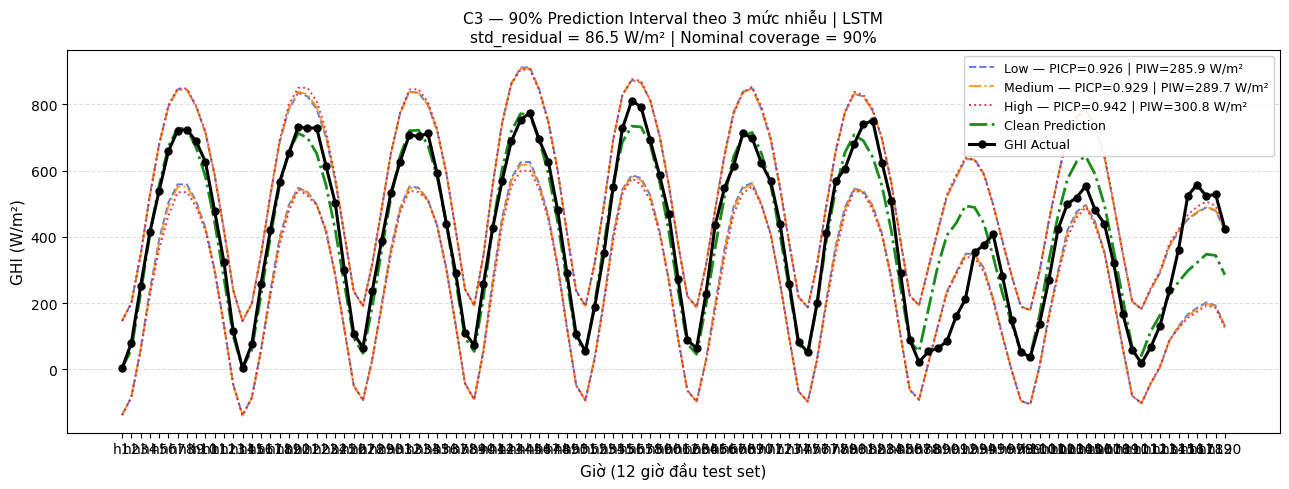

In [ ]:
N_HOURS = 120
t = np.arange(N_HOURS)

all_preds_by_level = {}
for level_name, sigmas_plot in NOISE_LEVELS.items():
    preds = []
    for seed in range(N_REPEAT):
        X_noisy_raw = inject_noise(
            X_test, FEATURES, sigmas_plot,
            FEATURE_PROB, FEATURE_CLIP,
            PERTURB_RATE, seed
        )
        X_noisy_sc = scaler.transform(X_noisy_raw)
        ghi_noisy  = predict_ghi_from_noisy(
            ROBUST_MODEL, X_noisy_raw, X_noisy_sc, H0_test
        )
        preds.append(ghi_noisy)
    all_preds_by_level[level_name] = np.array(preds)

# ── Config ───────────────────────────────────────────────────────
level_styles = {
    'low'   : ('royalblue',  '--'),
    'medium': ('darkorange', '-.'),
    'high'  : ('crimson',    ':' ),
}

fig, ax = plt.subplots(figsize=(13, 5))

for level_name, (color, ls) in level_styles.items():
    ap  = all_preds_by_level[level_name]
    r   = exp_results[list(NOISE_LEVELS.keys()).index(level_name)]

    ghi_mean_lv  = np.mean(ap, axis=0)
    std_input_lv = np.std(ap,  axis=0)
    std_total_lv = np.sqrt(std_input_lv[:N_HOURS]**2 + std_residual**2)

    lower_c3 = ghi_mean_lv[:N_HOURS] - 1.645 * std_total_lv
    upper_c3 = ghi_mean_lv[:N_HOURS] + 1.645 * std_total_lv

    # Vẽ 2 đường biên interval
    ax.plot(t, lower_c3, color=color, linewidth=1.4, linestyle=ls, alpha=0.85)
    ax.plot(t, upper_c3, color=color, linewidth=1.4, linestyle=ls, alpha=0.85,
            label=(f'{level_name.capitalize()} — '
                   f'PICP={r["PICP_C3"]:.3f} | PIW={r["PIW_C3"]:.1f} W/m²'))

# Clean prediction
ax.plot(t, ghi_clean[:N_HOURS],
        color='green', linewidth=2.0, linestyle='-.', alpha=0.9,
        label='Clean Prediction')

# Ground truth
ax.plot(t, ghi_true[:N_HOURS],
        color='black', linewidth=2.2, marker='o', markersize=5,
        label='GHI Actual')

# ── Formatting ───────────────────────────────────────────────────
ax.set_xlabel('Giờ (12 giờ đầu test set)', fontsize=11)
ax.set_ylabel('GHI (W/m²)', fontsize=11)
ax.set_title(
    f'C3 — 90% Prediction Interval theo 3 mức nhiễu | {ROBUST_MODEL}\n'
    f'std_residual = {std_residual:.1f} W/m² | Nominal coverage = 90%',
    fontsize=11
)
ax.set_xticks(t)
ax.set_xticklabels([f'h{i+1}' for i in t])
ax.legend(loc='upper right', fontsize=9, framealpha=0.9)
ax.grid(axis='y', linestyle='--', alpha=0.4)

plt.tight_layout()
plt.show()

In [ ]:
from scipy import stats

stat, p = stats.shapiro(residuals_val[:500])  # Shapiro-Wilk
skew    = stats.skew(residuals_val)
kurt    = stats.kurtosis(residuals_val)

print(f"Shapiro p-value : {p:.4f}  ({'Normal ✅' if p > 0.05 else 'NOT Normal ⚠️'})")
print(f"Skewness        : {skew:.4f}")
print(f"Kurtosis        : {kurt:.4f}")

Shapiro p-value : 0.0000  (NOT Normal ⚠️)
Skewness        : -0.8096
Kurtosis        : 3.2124


In [ ]:
# ── C3: Locally Weighted Conformal Prediction (Hour + SZA) ───────
from sklearn.neighbors import NearestNeighbors
from sklearn.preprocessing import StandardScaler

ALPHA       = 0.10
K_NEIGHBORS = 50

# ── Lấy (hour, SZA) từ val và test ──────────────────────────────
hour_col = FEATURES.index('hour_sin')   # dùng hour_sin, hour_cos

# Dùng hour_sin, hour_cos, SZA → 3 chiều
# hour_sin/cos giữ tính cyclic (23h gần 0h)
hour_sin_col = FEATURES.index('hour_sin')
hour_cos_col = FEATURES.index('hour_cos')

cond_val  = np.column_stack([
    X_val_seq[:, hour_sin_col],
    X_val_seq[:, hour_cos_col],
])   # shape: (n_val, 3)

cond_test = np.column_stack([
    X_test_seq[:, hour_sin_col],
    X_test_seq[:, hour_cos_col],
])   # shape: (n_test, 3)

# ── Scale để 3 chiều có đơn vị tương đương ───────────────────────
# hour_sin/cos đã trong [-1,1], SZA trong [0,90] → cần scale
scaler_cond = StandardScaler()
cond_val_sc  = scaler_cond.fit_transform(cond_val)
cond_test_sc = scaler_cond.transform(cond_test)

# ── Fit KNN trên (hour_sin, hour_cos, SZA) val ───────────────────
knn = NearestNeighbors(n_neighbors=K_NEIGHBORS, metric='euclidean')
knn.fit(cond_val_sc)

distances, indices = knn.kneighbors(cond_test_sc)
# indices shape: (n_test, K_NEIGHBORS)

# ── Residual của MLP trên val set (reuse từ C3 Prep) ─────────────
if ROBUST_MODEL == 'LSTM':
    residuals_val_cf = GHI_val[WINDOW:] - ghi_val_pred
else:
    residuals_val_cf = GHI_val - ghi_val_pred

# ── Tính interval per-sample ─────────────────────────────────────
lower_cf = np.zeros(len(cond_test_sc))
upper_cf = np.zeros(len(cond_test_sc))

for i in range(len(cond_test_sc)):
    neighbor_residuals = residuals_val_cf[indices[i]]   # (K,)
    q_lo_i = np.quantile(neighbor_residuals, ALPHA / 2)
    q_hi_i = np.quantile(neighbor_residuals, 1 - ALPHA / 2)

    lower_cf[i] = ghi_clean[i] + q_lo_i
    upper_cf[i] = ghi_clean[i] + q_hi_i

# ── Tích hợp noise uncertainty từ C2 ─────────────────────────────
print("══ C3 Conformal (Hour + SZA) — Per-Sample Interval ══\n")

for level_name in NOISE_LEVELS:
    ap           = all_preds_by_level[level_name]
    std_input_lv = np.std(ap, axis=0)

    lower_c3_cf = lower_cf - std_input_lv
    upper_c3_cf = upper_cf + std_input_lv

    picp_cf = np.mean((ghi_true >= lower_c3_cf) & (ghi_true <= upper_c3_cf))
    piw_cf  = np.mean(upper_c3_cf - lower_c3_cf)

    width_cf   = upper_c3_cf - lower_c3_cf
    pen_lo     = (2 / ALPHA) * np.maximum(lower_c3_cf - ghi_true, 0)
    pen_hi     = (2 / ALPHA) * np.maximum(ghi_true - upper_c3_cf, 0)
    winkler_cf = np.mean(width_cf + pen_lo + pen_hi)

    print(f"[{level_name:6s}] PICP={picp_cf:.3f} | "
          f"PIW={piw_cf:.1f} W/m² | "
          f"Winkler={winkler_cf:.2f}")

# ── Clean (không có noise) ────────────────────────────────────────
picp_clean_cf = np.mean((ghi_true >= lower_cf) & (ghi_true <= upper_cf))
piw_clean_cf  = np.mean(upper_cf - lower_cf)
print(f"\n[clean ] PICP={picp_clean_cf:.3f} | PIW={piw_clean_cf:.1f} W/m²")

# ── Coverage theo giờ ─────────────────────────────────────────────
print("\n── Coverage theo giờ (clean interval) ──")
test_mask = (df_fe['datetime_vn'] >= '2025-09-01')
test_hours = df_fe.loc[test_mask, 'hour'].values
if ROBUST_MODEL == 'LSTM':
    test_hours = test_hours[WINDOW:]

for h in sorted(set(test_hours)):
    mask_h  = (test_hours == h)
    covered = ((ghi_true[mask_h] >= lower_cf[mask_h]) &
               (ghi_true[mask_h] <= upper_cf[mask_h]))
    print(f"  Hour {h:02d} | PICP={covered.mean():.3f} | "
          f"PIW={np.mean(upper_cf[mask_h]-lower_cf[mask_h]):.1f} W/m² | "
          f"n={mask_h.sum()}")

══ C3 Conformal (Hour + SZA) — Per-Sample Interval ══

[low   ] PICP=0.887 | PIW=218.9 W/m² | Winkler=314.78
[medium] PICP=0.903 | PIW=232.0 W/m² | Winkler=312.81
[high  ] PICP=0.924 | PIW=254.6 W/m² | Winkler=314.65

[clean ] PICP=0.851 | PIW=204.6 W/m²

── Coverage theo giờ (clean interval) ──
  Hour 06 | PICP=0.889 | PIW=45.4 W/m² | n=108
  Hour 07 | PICP=0.694 | PIW=74.2 W/m² | n=121
  Hour 08 | PICP=0.826 | PIW=150.9 W/m² | n=121
  Hour 09 | PICP=0.835 | PIW=230.9 W/m² | n=121
  Hour 10 | PICP=0.843 | PIW=296.9 W/m² | n=121
  Hour 11 | PICP=0.843 | PIW=322.3 W/m² | n=121
  Hour 12 | PICP=0.835 | PIW=322.3 W/m² | n=121
  Hour 13 | PICP=0.826 | PIW=307.4 W/m² | n=121
  Hour 14 | PICP=0.835 | PIW=250.0 W/m² | n=121
  Hour 15 | PICP=0.860 | PIW=204.3 W/m² | n=121
  Hour 16 | PICP=0.926 | PIW=159.4 W/m² | n=121
  Hour 17 | PICP=1.000 | PIW=77.3 W/m² | n=121
  Hour 18 | PICP=1.000 | PIW=38.1 W/m² | n=2
